# Assess abx x bacteroides x glucose dysreg
This notebook should show that we can't really link the drug x glucose relationship to Bacteroides -- CLR isn't sensitive enough / 16S as good at MGX

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from regression_functions import *
from scipy.stats import spearmanr
import scipy.stats.mstats
import arivale_data_interface as adi
adi.apply_isb_config()

In [2]:
abx_microbes = pd.read_csv('data/rh_microbes_clr.csv', dtype={'public_client_id':str})
abx_microbes = abx_microbes.set_index(['public_client_id','vendor_dashboard'])
abx_microbes = abx_microbes.iloc[:, 26:]
abx_microbes.reset_index(inplace = True)

In [3]:
abx_microbes

,public_client_id,vendor_dashboard,Bacteria_Actinobacteria_Actinobacteria_Bifidobacteriales_Bifidobacteriaceae_Bifidobacterium,Bacteria_Actinobacteria_Actinobacteria_Micrococcales_Micrococcaceae_Rothia,Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Atopobium,Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriaceae_Collinsella,Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_Raoultibacter,Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_nan,Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Adlercreutzia,Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_DNF00809,...,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Oxalobacter,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Parasutterella,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Sutterella,Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella,Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Klebsiella,Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Cloacibacillus,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia
0,01568974,Second Genome,9.195676,NaN,NaN,6.296003,NaN,4.768723,NaN,NaN,...,NaN,NaN,NaN,4.089562,NaN,4.061391,NaN,NaN,NaN,NaN
1,01092042,Second Genome,4.563042,NaN,2.422975,6.240688,NaN,2.828440,NaN,NaN,...,NaN,2.135293,8.694672,2.135293,NaN,4.674267,NaN,NaN,NaN,4.958654
2,01601230,Second Genome,NaN,NaN,NaN,5.703509,NaN,4.176136,NaN,NaN,...,2.876853,3.815122,7.724533,3.452217,NaN,NaN,NaN,NaN,NaN,6.791096
3,01684342,Second Genome,8.850668,NaN,NaN,5.792607,NaN,5.381693,NaN,NaN,...,NaN,3.116645,8.338707,2.657113,NaN,2.880257,NaN,NaN,5.376213,5.965220
4,01789632,Second Genome,2.788787,NaN,NaN,3.705078,NaN,4.734697,3.561977,4.580546,...,4.452292,5.327761,6.000974,NaN,NaN,3.265711,NaN,6.490089,6.752770,7.615766
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1965,HX883708,research-microbiome,NaN,0.351627,NaN,NaN,NaN,5.338652,6.362894,4.682360,...,NaN,7.021125,NaN,1.604390,NaN,NaN,NaN,NaN,NaN,NaN
1966,01201199,research-microbiome,NaN,NaN,NaN,7.195134,NaN,NaN,5.557525,3.403976,...,NaN,7.075396,NaN,NaN,NaN,NaN,NaN,4.289014,4.449944,NaN
1967,01440344,research-microbiome,8.954861,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,8.442398,NaN,5.212057,NaN,NaN,NaN,NaN,NaN,NaN
1968,01382823,research-microbiome,8.349165,NaN,1.513550,NaN,NaN,5.767744,6.924303,4.529085,...,NaN,7.968749,NaN,2.612163,NaN,NaN,NaN,NaN,NaN,8.683670


In [4]:
abx_covar = pd.read_csv("data/abx_recency_covariates_all.csv", dtype={'public_client_id':str})

In [5]:
# Merge with measure
abx_microbes_covar = abx_covar.merge(
    abx_microbes,
    how='left',
    on="public_client_id").dropna(
    subset="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides")
abx_microbes_covar

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Oxalobacter,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Parasutterella,Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Sutterella,Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella,Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Klebsiella,Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Cloacibacillus,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia
1,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,...,NaN,NaN,NaN,4.089562,NaN,4.061391,NaN,NaN,NaN,NaN
2,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,...,NaN,2.135293,8.694672,2.135293,NaN,4.674267,NaN,NaN,NaN,4.958654
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,2.876853,3.815122,7.724533,3.452217,NaN,NaN,NaN,NaN,NaN,6.791096
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,NaN,3.116645,8.338707,2.657113,NaN,2.880257,NaN,NaN,5.376213,5.965220
6,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,4.452292,5.327761,6.000974,NaN,NaN,3.265711,NaN,6.490089,6.752770,7.615766
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2656,HX883708,0.064444,-0.026034,-0.038521,0.062859,0.053261,452.0,No,No,three,...,NaN,7.021125,NaN,1.604390,NaN,NaN,NaN,NaN,NaN,NaN
2662,01201199,0.065988,-0.013680,-0.050926,0.044681,0.035107,712.0,No,No,three,...,NaN,7.075396,NaN,NaN,NaN,NaN,NaN,4.289014,4.449944,NaN
2663,01440344,-0.490879,-0.196570,-0.115884,-0.019040,0.133794,731.0,No,Yes,three,...,NaN,8.442398,NaN,5.212057,NaN,NaN,NaN,NaN,NaN,NaN
2664,01382823,0.065718,-0.021335,-0.035135,0.089997,0.031969,752.0,No,No,three,...,NaN,7.968749,NaN,2.612163,NaN,NaN,NaN,NaN,NaN,8.683670


**Add statins**

In [6]:
statin_users = pd.read_csv('data/arivale_statin_users.csv', dtype={"public_client_id":str, "days_in_program":float})

In [7]:
statin_users = statin_users.sort_values(by="days_in_program")
abx_microbes_covar = abx_microbes_covar.sort_values(by="days_in_program")

In [8]:
# Merge with all
abx_statins = pd.merge_asof(
    abx_microbes_covar, statin_users, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

In [9]:
abx_statins['statin_binary'] = abx_statins['statin'].notna().astype(int)

**Add labs**

In [10]:
labs_clean = pd.read_csv("data/clincal_chems_abx_users_clean.csv", 
                         dtype={"public_client_id":str, "days_in_program":float})

labs_clean.set_index(['public_client_id','days_in_program'], inplace=True)

labs = ['HOMA_IR', 'QUICKI', 'GLYCOHEMOGLOBINA1C',
        'HDLPARTICLENUMBER', 'LDLPARTICLENUMBER', 'vendor']

labs_clean_small = labs_clean[labs]

abx_statins_labs = pd.merge_asof(
    abx_statins,
    labs_clean_small,
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

In [11]:
abx_statins_labs['abx_year'] = abx_statins_labs['abx_recency'].apply(lambda x: 0 if x == "none" else 1)

## Move onto Bacteroides-Statin relationship

In [12]:
# abx_statins_labs.columns[abx_statins_labs.columns.str.contains("Bacteroides")]

In [13]:
abx_statins_labs['centered_bac_clr'] = abx_statins_labs['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides'].apply(
    lambda x: x - (abx_statins_labs['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides']).mean())

### Bacteroides & HbA1c relationship, faceted by T2DM status and statin use

In [14]:
no_abx = abx_statins_labs[abx_statins_labs.abx_year == 0].copy()

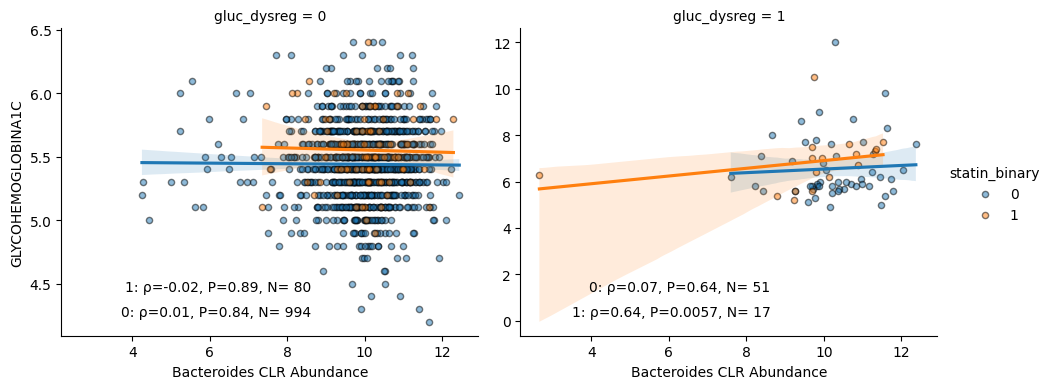

In [15]:
g = sns.lmplot(
    data=no_abx,
    x="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides",
    y="GLYCOHEMOGLOBINA1C",
    col="gluc_dysreg", 
    hue="statin_binary",
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        "alpha": 0.5
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)
g.set_axis_labels("Bacteroides CLR Abundance")

# Loop through each facet
for (col_val), ax in g.axes_dict.items():
    facet_df = no_abx[(no_abx["gluc_dysreg"] == col_val)]
    y = 0.1   # starting height for annotations

    for hue_val in facet_df["statin_binary"].unique():

        subset = facet_df[facet_df["statin_binary"] == hue_val][[
                "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides"], subset["GLYCOHEMOGLOBINA1C"])
            n_hue = len(subset)

            ax.text(
                0.6, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.2g}, N={n_hue: .4g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y += 0.08

In [16]:
no_statin = abx_statins_labs[abx_statins_labs.statin_binary == 0].copy()

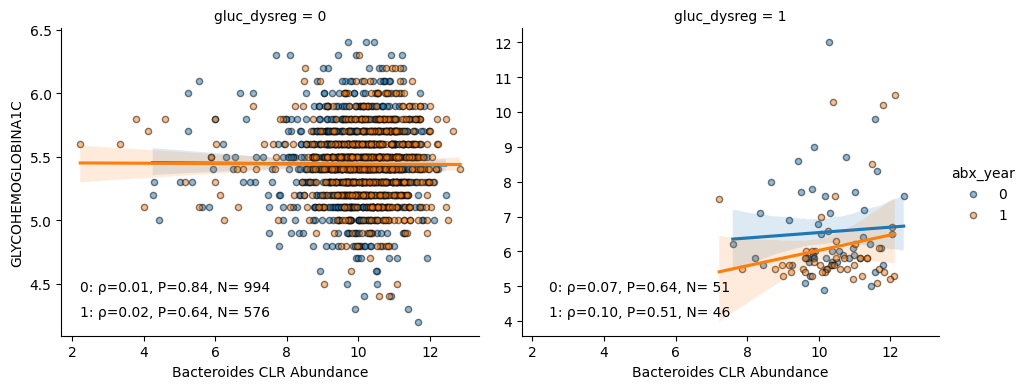

In [17]:
g = sns.lmplot(
    data=no_statin,
    x="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides",
    y="GLYCOHEMOGLOBINA1C",
    col="gluc_dysreg", 
    hue="abx_year",
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        "alpha": 0.5
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)
g.set_axis_labels("Bacteroides CLR Abundance")

# Loop through each facet
for (col_val), ax in g.axes_dict.items():
    facet_df = no_statin[(no_statin["gluc_dysreg"] == col_val)]
    y = 0.1   # starting height for annotations

    for hue_val in facet_df["abx_year"].unique():

        subset = facet_df[facet_df["abx_year"] == hue_val][[
                "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides"], subset["GLYCOHEMOGLOBINA1C"])
            n_hue = len(subset)

            ax.text(
                0.5, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.2g}, N={n_hue: .4g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y += 0.08

In [18]:
hba1c_statin_abx_bacteroides = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                           'C(gluc_dysreg) + PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) + C(vendor_dashboard) +'
                           'C(statin_binary)*C(abx_year)*centered_bac_clr')

hba1c_model = ols(hba1c_statin_abx_bacteroides, data=abx_statins_labs).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.373
Model:                            OLS   Adj. R-squared:                  0.366
Method:                 Least Squares   F-statistic:                     57.12
Date:                Fri, 10 Jul 2026   Prob (F-statistic):          3.12e-169
Time:                        12:01:08   Log-Likelihood:                -1038.9
No. Observations:                1847   AIC:                             2118.
Df Residuals:                    1827   BIC:                             2228.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
===========================================================================================================================
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   4.6368      0.071     65.048      0.000       4.497       4.777
C(sex)[T.M]                                                 0.0334      0.022      1.551      0.121      -0.009       0.076
C(gluc_dysreg)[T.1]                                         0.8652      0.040     21.725      0.000       0.787       0.943
C(vendor)[T.Quest]                                         -0.2002      0.032     -6.290      0.000      -0.263      -0.138
C(vendor_dashboard)[T.research-microbiome]                 -0.0533      0.027     -1.962      0.050      -0.107   -7.59e-06
C(statin_binary)[T.1]                                       0.0743      0.047      1.570      0.117      -0.019       0.167
C(abx_year)[T.1]                                           -0.0452      0.022     -2.063      0.039      -0.088      -0.002
C(statin_binary)[T.1]:C(abx_year)[T.1]                      0.0654      0.068      0.957      0.338      -0.069       0.199
age                                                         0.0100      0.001      9.571      0.000       0.008       0.012
BMI_CALC                                                    0.0150      0.002      8.872      0.000       0.012       0.018
centered_eGFR                                               0.0013      0.001      1.587      0.113      -0.000       0.003
PC1                                                        -0.3815      0.075     -5.119      0.000      -0.528      -0.235
PC2                                                         0.2767      0.067      4.123      0.000       0.145       0.408
PC3                                                         0.1425      0.077      1.843      0.066      -0.009       0.294
PC4                                                         0.1536      0.075      2.045      0.041       0.006       0.301
PC5                                                        -0.1347      0.068     -1.985      0.047      -0.268      -0.002
centered_bac_clr                                           -0.0006      0.013     -0.049      0.961      -0.026       0.024
C(statin_binary)[T.1]:centered_bac_clr                      0.0608      0.039      1.571      0.116      -0.015       0.137
C(abx_year)[T.1]:centered_bac_clr                          -0.0039      0.018     -0.213      0.832      -0.040       0.032
C(statin_binary)[T.1]:C(abx_year)[T.1]:centered_bac_clr    -0.0241      0.054     -0.444      0.657      -0.131       0.082
==============================================================================
Omnibus:                     1591.588   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           10798

In [19]:
hba1c_statin_bacteroides_dm = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                           'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) + C(vendor_dashboard) +'
                           'C(statin_binary)*C(gluc_dysreg)*centered_bac_clr')

hba1c_model = ols(hba1c_statin_bacteroides_dm, data=no_abx).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.400
Method:                 Least Squares   F-statistic:                     43.29
Date:                Fri, 10 Jul 2026   Prob (F-statistic):          6.55e-115
Time:                        12:02:20   Log-Likelihood:                -577.61
No. Observations:                1142   AIC:                             1193.
Df Residuals:                    1123   BIC:                             1289.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
==============================================================================================================================
                                                                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------
Intercept                                                      4.6948      0.088     53.591      0.000       4.523       4.867
C(sex)[T.M]                                                    0.0429      0.026      1.675      0.094      -0.007       0.093
C(vendor)[T.Quest]                                            -0.2312      0.037     -6.200      0.000      -0.304      -0.158
C(vendor_dashboard)[T.research-microbiome]                    -0.0823      0.032     -2.538      0.011      -0.146      -0.019
C(statin_binary)[T.1]                                          0.0317      0.049      0.644      0.520      -0.065       0.128
C(gluc_dysreg)[T.1]                                            0.9972      0.061     16.426      0.000       0.878       1.116
C(statin_binary)[T.1]:C(gluc_dysreg)[T.1]                      0.2491      0.126      1.981      0.048       0.002       0.496
age                                                            0.0097      0.001      7.539      0.000       0.007       0.012
BMI_CALC                                                       0.0138      0.002      6.417      0.000       0.010       0.018
centered_eGFR                                                  0.0021      0.001      2.148      0.032       0.000       0.004
PC1                                                           -0.3753      0.089     -4.218      0.000      -0.550      -0.201
PC2                                                            0.2464      0.080      3.069      0.002       0.089       0.404
PC3                                                            0.0699      0.095      0.735      0.462      -0.117       0.257
PC4                                                            0.2478      0.091      2.728      0.006       0.070       0.426
PC5                                                           -0.2844      0.095     -2.986      0.003      -0.471      -0.098
centered_bac_clr                                              -0.0058      0.013     -0.464      0.642      -0.031       0.019
C(statin_binary)[T.1]:centered_bac_clr                        -0.0076      0.049     -0.153      0.879      -0.105       0.089
C(gluc_dysreg)[T.1]:centered_bac_clr                           0.0770      0.057      1.347      0.178      -0.035       0.189
C(statin_binary)[T.1]:C(gluc_dysreg)[T.1]:centered_bac_clr     0.0989      0.090      1.094      0.274      -0.079       0.276
==============================================================================
Omnibus:                      932.390   Durbin-Watson:                   1.926
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            70612.910
Skew:                           3.210   Prob(JB):   

In [20]:
hba1c_abx_bacteroides_dm = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                           'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) + C(vendor_dashboard) +'
                           'C(gluc_dysreg)*C(abx_year)*centered_bac_clr')

hba1c_model = ols(hba1c_abx_bacteroides_dm, data=no_statin).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.331
Model:                            OLS   Adj. R-squared:                  0.324
Method:                 Least Squares   F-statistic:                     45.38
Date:                Fri, 10 Jul 2026   Prob (F-statistic):          7.12e-130
Time:                        12:04:26   Log-Likelihood:                -838.26
No. Observations:                1667   AIC:                             1715.
Df Residuals:                    1648   BIC:                             1817.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
=========================================================================================================================
                                                            coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                 4.6881      0.069     67.474      0.000       4.552       4.824
C(sex)[T.M]                                               0.0576      0.021      2.685      0.007       0.016       0.100
C(vendor)[T.Quest]                                       -0.2215      0.032     -6.960      0.000      -0.284      -0.159
C(vendor_dashboard)[T.research-microbiome]               -0.0602      0.027     -2.226      0.026      -0.113      -0.007
C(gluc_dysreg)[T.1]                                       1.0026      0.060     16.725      0.000       0.885       1.120
C(abx_year)[T.1]                                         -0.0121      0.021     -0.566      0.571      -0.054       0.030
C(gluc_dysreg)[T.1]:C(abx_year)[T.1]                     -0.4758      0.088     -5.392      0.000      -0.649      -0.303
age                                                       0.0101      0.001      9.827      0.000       0.008       0.012
BMI_CALC                                                  0.0126      0.002      7.608      0.000       0.009       0.016
centered_eGFR                                             0.0013      0.001      1.547      0.122      -0.000       0.003
PC1                                                      -0.3954      0.073     -5.435      0.000      -0.538      -0.253
PC2                                                       0.2746      0.066      4.175      0.000       0.146       0.404
PC3                                                       0.1044      0.076      1.369      0.171      -0.045       0.254
PC4                                                       0.1846      0.077      2.412      0.016       0.034       0.335
PC5                                                      -0.1307      0.068     -1.929      0.054      -0.264       0.002
centered_bac_clr                                         -0.0052      0.012     -0.421      0.674      -0.029       0.019
C(gluc_dysreg)[T.1]:centered_bac_clr                      0.0810      0.057      1.426      0.154      -0.030       0.192
C(abx_year)[T.1]:centered_bac_clr                        -0.0041      0.018     -0.233      0.816      -0.039       0.031
C(gluc_dysreg)[T.1]:C(abx_year)[T.1]:centered_bac_clr     0.0964      0.080      1.208      0.227      -0.060       0.253
==============================================================================
Omnibus:                     1476.590   Durbin-Watson:                   1.981
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           120873.517
Skew:                           3.734   Prob(JB):                         0.00
Kurtosis:                      44.042   Cond. No.                         607.
====

**Okay now remove those with glucose dysreg history**

In [21]:
no_hx = abx_statins_labs[abx_statins_labs.gluc_dysreg == 0].copy()

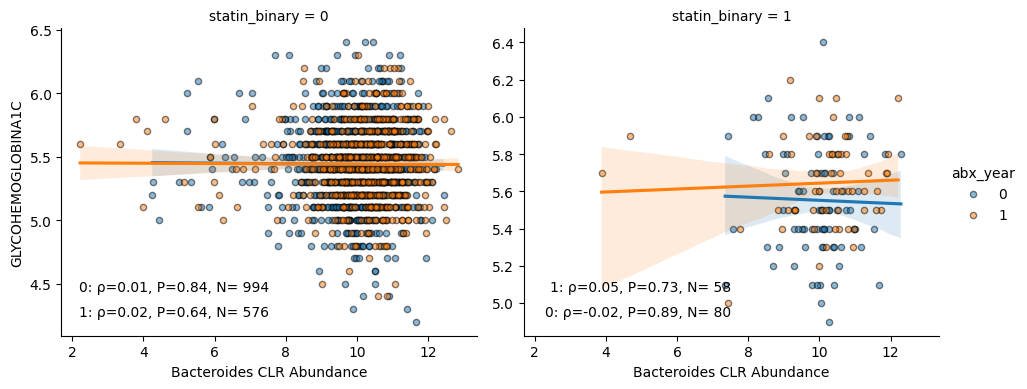

In [22]:
g = sns.lmplot(
    data=no_hx,
    x="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides",
    y="GLYCOHEMOGLOBINA1C",
    col="statin_binary", 
    hue="abx_year",
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        "alpha": 0.5
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)
g.set_axis_labels("Bacteroides CLR Abundance")

# Loop through each facet
for (col_val), ax in g.axes_dict.items():
    facet_df = no_hx[(no_hx["statin_binary"] == col_val)]
    y = 0.1   # starting height for annotations

    for hue_val in facet_df["abx_year"].unique():

        subset = facet_df[facet_df["abx_year"] == hue_val][[
                "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides"], subset["GLYCOHEMOGLOBINA1C"])
            n_hue = len(subset)

            ax.text(
                0.5, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.2g}, N={n_hue: .4g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y += 0.08

In [23]:
hba1c_abx_statin_hc = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                           'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) + C(vendor_dashboard) +'
                           'C(statin_binary)*C(abx_year)*centered_bac_clr')

hba1c_model = ols(hba1c_abx_statin_hc, data=no_hx).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.280
Model:                            OLS   Adj. R-squared:                  0.272
Method:                 Least Squares   F-statistic:                     36.43
Date:                Fri, 10 Jul 2026   Prob (F-statistic):          1.23e-106
Time:                        12:10:07   Log-Likelihood:                -129.36
No. Observations:                1708   AIC:                             296.7
Df Residuals:                    1689   BIC:                             400.1
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
===========================================================================================================================
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   4.8213      0.046    105.687      0.000       4.732       4.911
C(sex)[T.M]                                                 0.0104      0.014      0.763      0.446      -0.016       0.037
C(vendor)[T.Quest]                                         -0.2408      0.020    -11.965      0.000      -0.280      -0.201
C(vendor_dashboard)[T.research-microbiome]                 -0.0615      0.017     -3.528      0.000      -0.096      -0.027
C(statin_binary)[T.1]                                       0.0345      0.031      1.096      0.273      -0.027       0.096
C(abx_year)[T.1]                                           -0.0113      0.014     -0.812      0.417      -0.039       0.016
C(statin_binary)[T.1]:C(abx_year)[T.1]                      0.0757      0.047      1.594      0.111      -0.017       0.169
age                                                         0.0094      0.001     14.008      0.000       0.008       0.011
BMI_CALC                                                    0.0098      0.001      8.980      0.000       0.008       0.012
centered_eGFR                                               0.0002      0.001      0.401      0.688      -0.001       0.001
PC1                                                        -0.4066      0.048     -8.498      0.000      -0.500      -0.313
PC2                                                         0.1903      0.045      4.275      0.000       0.103       0.278
PC3                                                         0.2095      0.050      4.204      0.000       0.112       0.307
PC4                                                         0.1283      0.047      2.711      0.007       0.035       0.221
PC5                                                        -0.0510      0.044     -1.165      0.244      -0.137       0.035
centered_bac_clr                                           -0.0082      0.008     -1.023      0.306      -0.024       0.008
C(statin_binary)[T.1]:centered_bac_clr                     -0.0120      0.032     -0.376      0.707      -0.075       0.051
C(abx_year)[T.1]:centered_bac_clr                          -0.0019      0.012     -0.162      0.871      -0.025       0.021
C(statin_binary)[T.1]:C(abx_year)[T.1]:centered_bac_clr     0.0317      0.041      0.778      0.437      -0.048       0.112
==============================================================================
Omnibus:                       56.441   Durbin-Watson:                   2.064
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              111.918
Skew:                          -0.217   Prob(JB):                     4.98e-25
Kurtosis:                       4.176  

**What could be different between the Arivale and MetaCardis cohorts?**
- Obviously, Bacteroides estimated absolute abundance is miles better than the CLR abundance
- I also notice that the CLR abundance, particularly for the Statin users, is mostly constrained above 8 (on x-axis). The estimated absolute counts, however,   have a much nicer spread over a ranger range of measured values
- The percentage of individuals in the Arivale cohort that have T2DM is quite small compared to the percentage in MetaCardis. That cohort is designed to study cardiometabolic disease, so it makes sense that they could be enriched for different health phenotypes

In [51]:
# Bacteroides is very prevalent in our cohort
abx_microbes_status['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides'].isna().sum()

7

In [52]:
# Interestingly, not many statin users with T2DM
# Likely driven by T2DM being a smaller percentage of the cohort
pd.crosstab(abx_microbes_status['t2dm_reclass_meds'], abx_microbes_status['statin_binary'])

statin_binary,0,1
t2dm_reclass_meds,,
False,1713,148
True,66,43


In [53]:
pd.crosstab(abx_microbes_status['abx_year'], abx_microbes_status['statin_binary'])

statin_binary,0,1
abx_year,,
0,1117,104
1,662,87


### Bacteroides & HbA1c relationship
- Rows at T2DM status
- Cols are statin use
- Hue is abx use in the last year
- Added spearman rho, p, and N

In [54]:
abx_microbes_status.Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides.describe()

count    1963.000000
mean       10.047058
std         1.167136
min         2.226785
25%         9.531884
50%        10.145743
75%        10.789918
max        12.841378
Name: Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides, dtype: float64

In [55]:
abx_microbes_status['centered_bac_clr'] = abx_microbes_status['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides'].apply(
    lambda x: x - (abx_microbes_status['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides']).mean())

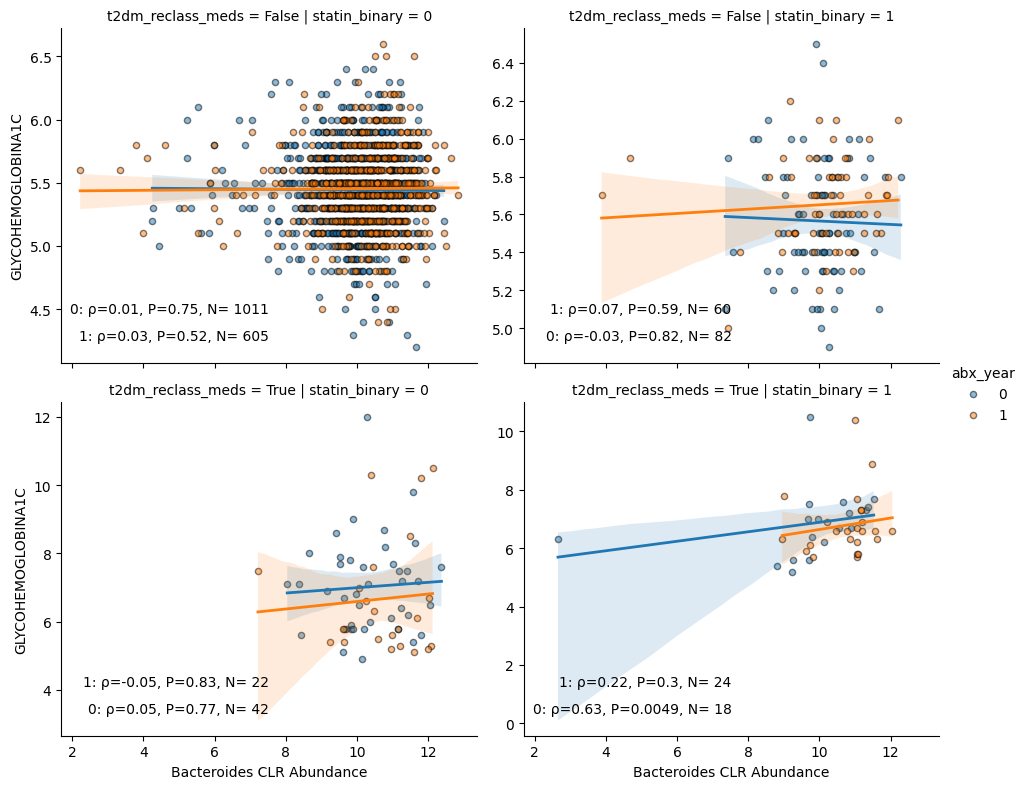

In [56]:
g = sns.lmplot(
    data=abx_microbes_status,
    x="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides",
    y="GLYCOHEMOGLOBINA1C",
    col="statin_binary",      
    row="t2dm_reclass_meds",   
    hue="abx_year",
    #palette={}
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        #"linewidth": 0.5,
        "alpha": 0.5
    },
    line_kws={
        "linewidth": 2
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)

g.set_axis_labels("Bacteroides CLR Abundance")


for (row_val, col_val), ax in g.axes_dict.items():

    facet_df = abx_microbes_status[
        (abx_microbes_status["t2dm_reclass_meds"] == row_val) &
        (abx_microbes_status["statin_binary"] == col_val)
    ]

    y = 0.1   # starting height for annotations

    for hue_val in facet_df["abx_year"].unique():

        subset = facet_df[facet_df["abx_year"] == hue_val][[
                "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides"], subset["GLYCOHEMOGLOBINA1C"])
            n_hue = len(subset)

            ax.text(
                0.5, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.2g}, N={n_hue: .4g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y += 0.08

In [57]:
hba1c_statin_abx_bacteroides = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                           'C(t2dm_reclass_meds) + PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) +'
                           'C(statin_binary)*C(abx_year)')

hba1c_model = ols(hba1c_statin_abx_bacteroides, data=abx_microbes_status).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.450
Model:                            OLS   Adj. R-squared:                  0.446
Method:                 Least Squares   F-statistic:                     108.5
Date:                Thu, 09 Jul 2026   Prob (F-statistic):          6.99e-229
Time:                        13:56:40   Log-Likelihood:                -1009.4
No. Observations:                1870   AIC:                             2049.
Df Residuals:                    1855   BIC:                             2132.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
==========================================================================================================
                                             coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                                  4.6683      0.067     70.156      0.000       4.538       4.799
C(sex)[T.M]                                0.0055      0.021      0.266      0.790      -0.035       0.046
C(t2dm_reclass_meds)[T.True]               1.2399      0.045     27.793      0.000       1.152       1.327
C(vendor)[T.Quest]                        -0.1700      0.024     -7.060      0.000      -0.217      -0.123
C(statin_binary)[T.1]                      0.0210      0.045      0.462      0.644      -0.068       0.110
C(abx_year)[T.1]                          -0.0284      0.021     -1.342      0.180      -0.070       0.013
C(statin_binary)[T.1]:C(abx_year)[T.1]     0.0521      0.065      0.797      0.425      -0.076       0.180
age                                        0.0100      0.001      9.844      0.000       0.008       0.012
BMI_CALC                                   0.0131      0.002      8.047      0.000       0.010       0.016
centered_eGFR                              0.0012      0.001      1.544      0.123      -0.000       0.003
PC1                                       -0.4381      0.072     -6.105      0.000      -0.579      -0.297
PC2                                        0.2573      0.064      4.033      0.000       0.132       0.383
PC3                                        0.1834      0.075      2.449      0.014       0.037       0.330
PC4                                        0.1839      0.073      2.532      0.011       0.041       0.326
PC5                                       -0.1321      0.066     -2.016      0.044      -0.261      -0.004
==============================================================================
Omnibus:                     1289.936   Durbin-Watson:                   2.023
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            67750.789
Skew:                           2.620   Prob(JB):                         0.00
Kurtosis:                      32.018   Cond. No.                         456.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Last approach would be to look at alpha diversity as Tom did in his paper
- Berger-Parker is a measure of dominance, so I hypothesize, that it may be a good surrogate for Bacteroides dominant microbiomes
- Although, perhaps looking at enterosignatures would be better
- Tom looked at richness/number ASVs

In [58]:
alphas_rarefied = pd.read_csv("data/rh_abx_covar_alpha_divs_rarefied.csv", dtype={'public_client_id':str})[[
    'public_client_id',
    'observed_features', 
    'shannon_index',
    'berger_parker']].copy()

In [59]:
abx_microbes_alphas = abx_microbes_status.merge(alphas_rarefied, on='public_client_id', how='left')

## Look at relationship between observed features and HbA1c
- No hue for abx use yet
- Interested in seeing whether we can pick up on the statin effect

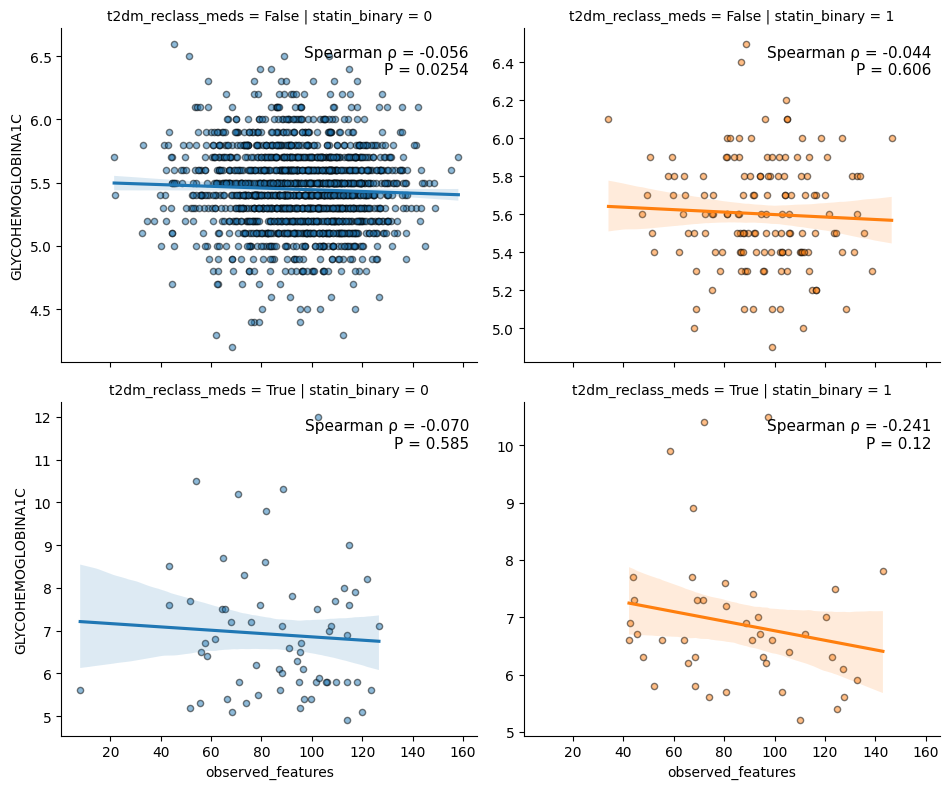

In [60]:
g = sns.lmplot(
    data=abx_microbes_alphas,
    x="observed_features",
    y="GLYCOHEMOGLOBINA1C",
    col="statin_binary",      # first faceting variable (columns)
    row="t2dm_reclass_meds",      # second faceting variable (rows)
    hue="statin_binary",      # optional
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        #"linewidth": 0.5,
        "alpha": 0.5
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)

# Loop through each facet
for (row_val, col_val), ax in g.axes_dict.items():

    subset = abx_microbes_alphas[
        (abx_microbes_alphas["t2dm_reclass_meds"] == row_val) &
        (abx_microbes_alphas["statin_binary"] == col_val)
    ]

    subset = subset[["observed_features", "GLYCOHEMOGLOBINA1C"]].dropna()

    if len(subset) > 2:
        rho, p = spearmanr(subset["observed_features"], subset["GLYCOHEMOGLOBINA1C"])
        ax.text(
            0.98, 0.95,
            f"Spearman ρ = {rho:.3f}\nP = {p:.3g}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=11
        )

**Next add abx hue**

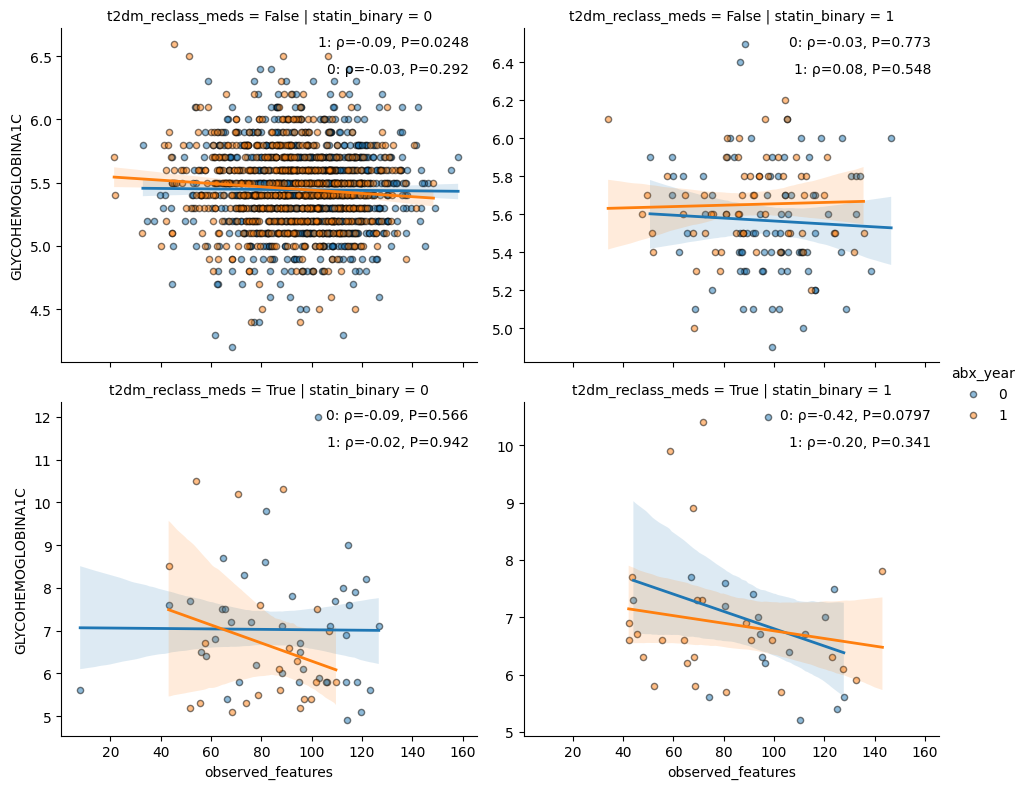

In [61]:
g = sns.lmplot(
    data=abx_microbes_alphas,
    x="observed_features",
    y="GLYCOHEMOGLOBINA1C",
    col="statin_binary",     
    row="t2dm_reclass_meds",  
    hue="abx_year",     
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        #"linewidth": 0.5,
        "alpha": 0.5
    },
    line_kws={
        "linewidth": 2
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)

for (row_val, col_val), ax in g.axes_dict.items():
    facet_df = abx_microbes_alphas[
        (abx_microbes_alphas["t2dm_reclass_meds"] == row_val) &
        (abx_microbes_alphas["statin_binary"] == col_val)
    ]

    y = 0.98   # starting height for annotations

    for hue_val in facet_df["abx_year"].dropna().unique():

        subset = facet_df[facet_df["abx_year"] == hue_val][[
            "observed_features", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["observed_features"], subset["GLYCOHEMOGLOBINA1C"])
            
            ax.text(
                0.98, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.3g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y -= 0.08

In [62]:
abx_microbes_alphas['c_obs_feats'] = abx_microbes_alphas['observed_features'].apply(lambda x: x - (abx_microbes_alphas['observed_features']).mean())

In [63]:
hba1c_statin_abx_obs = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                           'C(t2dm_reclass_meds) + PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) + C(vendor_dashboard)'
                           '+ c_obs_feats*C(statin_binary)*C(abx_year)')

hba1c_model = ols(hba1c_statin_abx_obs, data=abx_microbes_alphas).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.453
Model:                            OLS   Adj. R-squared:                  0.447
Method:                 Least Squares   F-statistic:                     80.51
Date:                Thu, 09 Jul 2026   Prob (F-statistic):          1.42e-225
Time:                        13:56:49   Log-Likelihood:                -1005.4
No. Observations:                1870   AIC:                             2051.
Df Residuals:                    1850   BIC:                             2162.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
======================================================================================================================
                                                         coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
Intercept                                              4.7152      0.070     67.380      0.000       4.578       4.852
C(sex)[T.M]                                            0.0020      0.021      0.095      0.924      -0.039       0.043
C(t2dm_reclass_meds)[T.True]                           1.2377      0.045     27.644      0.000       1.150       1.325
C(vendor)[T.Quest]                                    -0.2088      0.031     -6.738      0.000      -0.270      -0.148
C(vendor_dashboard)[T.research-microbiome]            -0.0465      0.026     -1.763      0.078      -0.098       0.005
C(statin_binary)[T.1]                                  0.0305      0.046      0.665      0.506      -0.060       0.121
C(abx_year)[T.1]                                      -0.0320      0.022     -1.484      0.138      -0.074       0.010
C(statin_binary)[T.1]:C(abx_year)[T.1]                 0.0357      0.068      0.526      0.599      -0.097       0.168
age                                                    0.0100      0.001      9.804      0.000       0.008       0.012
BMI_CALC                                               0.0127      0.002      7.543      0.000       0.009       0.016
centered_eGFR                                          0.0011      0.001      1.401      0.161      -0.000       0.003
PC1                                                   -0.4178      0.074     -5.680      0.000      -0.562      -0.274
PC2                                                    0.2696      0.064      4.200      0.000       0.144       0.395
PC3                                                    0.1700      0.075      2.255      0.024       0.022       0.318
PC4                                                    0.1844      0.073      2.539      0.011       0.042       0.327
PC5                                                   -0.1384      0.066     -2.103      0.036      -0.267      -0.009
c_obs_feats                                         6.584e-05      0.001      0.099      0.921      -0.001       0.001
c_obs_feats:C(statin_binary)[T.1]                     -0.0034      0.002     -1.554      0.120      -0.008       0.001
c_obs_feats:C(abx_year)[T.1]                          -0.0012      0.001     -1.170      0.242      -0.003       0.001
c_obs_feats:C(statin_binary)[T.1]:C(abx_year)[T.1]     0.0031      0.003      1.051      0.293      -0.003       0.009
==============================================================================
Omnibus:                     1298.668   Durbin-Watson:                   2.023
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            69198.688
Skew:                           2.643   Prob(JB):                         0.00
Kurtosis:                     

# Sensitivity Analysis: Look at larger N without ancestry and GFR covariates

In [64]:
expanded_counts = pd.read_csv("data/rh_abx_genus_level_counts_base_covar.csv", dtype={'public_client_id':str})

In [65]:
len(expanded_counts)

2002

In [66]:
expanded_counts.columns[expanded_counts.columns.str.contains("Eukaryota_")]

Index([], dtype='object')

In [67]:
expanded_counts.set_index(["public_client_id"], inplace=True)
relative_abundance = expanded_counts.div(expanded_counts.sum(axis=1), axis=0)

In [49]:
microbe_features = relative_abundance.columns

In [50]:
zero_mask = relative_abundance == 0                       # Which have zero count
min_nonzero = relative_abundance[~zero_mask].min().min()  # Find min
relative_abundance[zero_mask] = min_nonzero / 2           # Impute 0 counts with half of min

In [51]:
# Calculate geometric mean
relative_abundance['gmean'] = relative_abundance.apply(
    scipy.stats.mstats.gmean, axis=1, nan_policy='omit') 

# CLR transform
relative_abundance[microbe_features] = np.log(    # Log transform all but gmean column
    relative_abundance[microbe_features].divide(  # Divide all but gmean column
        relative_abundance['gmean'], axis=0))

# Drop helper column
relative_abundance.drop(["gmean"],axis=1,inplace=True)
relative_abundance.head()

,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_nan,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanomethylophilus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Acidimicrobiia_Microtrichales_nan_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinobaculum,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,...,Bacteria_Tenericutes_Mollicutes_EMP-G18_nan_nan,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Tenericutes_Mollicutes_nan_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_nan_nan_nan
public_client_id,,,,,,,,,,,,,,,,,,,,,
01001661,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,...,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,-1.031045,5.488505,-1.031045,-1.031045
01001798,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,2.833927,...,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075,-1.136075
01002183,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,...,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,-1.279866,7.246554,-1.279866,-1.279866
01002412,8.289757,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,4.786304,...,-1.582514,7.243326,-1.582514,-1.582514,-1.582514,-1.582514,-1.582514,2.746084,-1.582514,-1.582514
01002885,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,...,-1.369044,-1.369044,6.053284,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044,-1.369044


In [52]:
relative_abundance_masked = relative_abundance.copy()

In [53]:
relative_abundance_masked[zero_mask] = np.nan
relative_abundance_masked.head()

,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_nan,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanomethylophilus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Acidimicrobiia_Microtrichales_nan_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinobaculum,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,...,Bacteria_Tenericutes_Mollicutes_EMP-G18_nan_nan,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Tenericutes_Mollicutes_nan_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_nan_nan_nan
public_client_id,,,,,,,,,,,,,,,,,,,,,
01001661,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.488505,NaN,NaN
01001798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.833927,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
01002183,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.246554,NaN,NaN
01002412,8.289757,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.786304,...,NaN,7.243326,NaN,NaN,NaN,NaN,NaN,2.746084,NaN,NaN
01002885,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,6.053284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [56]:
base_covar = pd.read_csv("data/abx_covariates_with_statins_a1c_base_covars.csv",
                              dtype={'public_client_id':str})

In [57]:
microbes_base_covar = base_covar.merge(relative_abundance_masked, on="public_client_id")

In [62]:
microbes_base_covar['abx_year'] = microbes_base_covar['abx_recency'].apply(lambda x: 0 if x == "none" else 1)

In [59]:
microbes_base_covar["t2dm_reclass_meds"] = (
    (microbes_base_covar["meds_blood_sugar"] == "Yes") |             # If they use glucose meds
    (microbes_base_covar.public_client_id.isin(
        health_status[health_status["type2_diabetes_current"]==True].public_client_id)) |        # If they report t2dm    
    (microbes_base_covar["public_client_id"].isin(self_report)) |    # Future report of T2DM; perhaps mistake first time
    (microbes_base_covar["public_client_id"].isin(labs))             # Average of future A1c continue high
).astype(str)

In [60]:
microbes_base_covar['centered_bac_clr'] = microbes_base_covar['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides'].apply(
    lambda x: x - (microbes_base_covar['Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides']).mean())

In [68]:
len(microbes_base_covar.dropna(subset='Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides'))

1995

In [64]:
hba1c_statin_abx_basic = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + '
                           'C(t2dm_reclass_meds) + C(vendor) + C(vendor_dashboard)'
                           '+ centered_bac_clr*C(statin_binary)*C(abx_year)')

hba1c_model = ols(hba1c_statin_abx_basic, data=microbes_base_covar).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.424
Model:                            OLS   Adj. R-squared:                  0.420
Method:                 Least Squares   F-statistic:                     105.0
Date:                Mon, 06 Jul 2026   Prob (F-statistic):          4.96e-211
Time:                        21:34:23   Log-Likelihood:                -1020.7
No. Observations:                1867   AIC:                             2069.
Df Residuals:                    1853   BIC:                             2147.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
===========================================================================================================================
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   4.7944      0.065     74.044      0.000       4.667       4.921
C(sex)[T.M]                                                 0.0064      0.021      0.309      0.757      -0.034       0.047
C(t2dm_reclass_meds)[T.True]                                1.2430      0.045     27.537      0.000       1.154       1.332
C(vendor)[T.Quest]                                         -0.2274      0.031     -7.375      0.000      -0.288      -0.167
C(vendor_dashboard)[T.research-microbiome]                 -0.0445      0.027     -1.679      0.093      -0.097       0.007
C(statin_binary)[T.1]                                       0.0206      0.046      0.449      0.654      -0.069       0.110
C(abx_year)[T.1]                                           -0.0250      0.021     -1.167      0.243      -0.067       0.017
C(statin_binary)[T.1]:C(abx_year)[T.1]                      0.0303      0.066      0.461      0.645      -0.099       0.159
age                                                         0.0081      0.001      9.152      0.000       0.006       0.010
BMI_CALC                                                    0.0131      0.002      7.984      0.000       0.010       0.016
centered_bac_clr                                           -0.0045      0.012     -0.370      0.711      -0.029       0.020
centered_bac_clr:C(statin_binary)[T.1]                      0.0761      0.038      2.008      0.045       0.002       0.150
centered_bac_clr:C(abx_year)[T.1]                          -0.0034      0.018     -0.191      0.848      -0.038       0.032
centered_bac_clr:C(statin_binary)[T.1]:C(abx_year)[T.1]    -0.0578      0.050     -1.145      0.252      -0.157       0.041
==============================================================================
Omnibus:                     1291.701   Durbin-Watson:                   2.038
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            68830.724
Skew:                           2.627   Prob(JB):                         0.00
Kurtosis:                      32.278   Cond. No.                         436.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

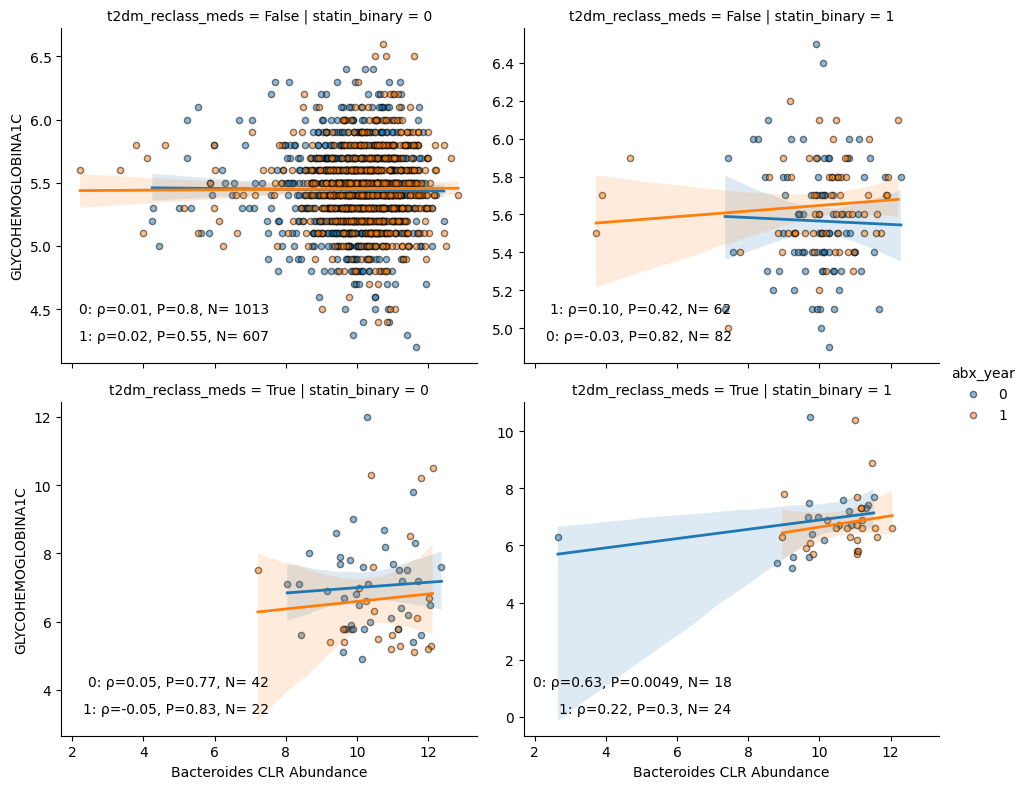

In [65]:
g = sns.lmplot(
    data=microbes_base_covar,
    x="Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides",
    y="GLYCOHEMOGLOBINA1C",
    col="statin_binary",      
    row="t2dm_reclass_meds",   
    hue="abx_year",
    scatter_kws={
        "s": 20,
        "edgecolor": "black",
        #"linewidth": 0.5,
        "alpha": 0.5
    },
    line_kws={
        "linewidth": 2
    },
    facet_kws={"sharey": False},
    height=4,
    aspect=1.2
)

g.set_axis_labels("Bacteroides CLR Abundance")


for (row_val, col_val), ax in g.axes_dict.items():

    facet_df = microbes_base_covar[
        (microbes_base_covar["t2dm_reclass_meds"] == row_val) &
        (microbes_base_covar["statin_binary"] == col_val)
    ]

    y = 0.1   # starting height for annotations

    for hue_val in facet_df["abx_year"].unique():

        subset = facet_df[facet_df["abx_year"] == hue_val][[
                "Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides", "GLYCOHEMOGLOBINA1C"]].dropna()

        if len(subset) > 2:
            rho, p = spearmanr(subset["Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides"], subset["GLYCOHEMOGLOBINA1C"])
            n_hue = len(subset)

            ax.text(
                0.5, y,
                f"{hue_val}: ρ={rho:.2f}, P={p:.2g}, N={n_hue: .4g}",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=10
            )

            y += 0.08